# Global COVID-19 Data Explorer
### Week 4 · Data Analytics and Machine Learning
**Guiding question:** How did reported COVID-19 outcomes differ across countries, and which country characteristics were associated with those differences?

This notebook follows all seven stages in the supplied Week 4 brief. Nigeria is compared with South Africa, India and the United Kingdom. Results describe **reported cumulative deaths**, not a causal measure of policy success.

**Run:** install `requirements.txt`, open this notebook, and select Restart Kernel and Run All. The supplied raw snapshot is reused; if absent, the notebook downloads the requested URL. Maps are interactive and also saved as standalone HTML. Internet access is needed to load Plotly's geographic boundaries. All other charts are embedded.


In [2]:
from pathlib import Path
import json, hashlib, sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pycountry
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for folder in ['data/raw', 'data/clean', 'outputs']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
OUT = ROOT / 'outputs'
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout(); plt.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight'); plt.show()


## Stage 1 · Types, pipeline and cleaning
**Pipeline:** collect an immutable raw snapshot → validate schema and country identifiers → audit missingness → construct latest-observed country summaries → explore distributions, time series and geography → evaluate models → communicate limitations.

The compact source uses `country` and `code`; these are normalized to `location` and `iso_code`. Country filtering uses ISO-3166 codes, plus OWID's Kosovo code, rather than assuming every three-letter code denotes a country. Territories are included where ISO-listed. Missing observations remain missing; no zero-filling of outcomes is performed.


In [4]:
URL = 'https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv'
raw_path = ROOT / 'data/raw/compact.csv'
metadata_path = ROOT / 'data/raw/source_metadata.json'
if not raw_path.exists():
    import urllib.request
    urllib.request.urlretrieve(URL, raw_path)
    metadata_path.write_text(json.dumps({'url': URL, 'downloaded_at_utc': datetime.now(timezone.utc).isoformat()}, indent=2))
raw = pd.read_csv(raw_path, low_memory=False)
sha256 = hashlib.sha256(raw_path.read_bytes()).hexdigest()
print(f'Raw shape: {raw.shape}; SHA-256: {sha256}')
display(raw.head())
df = raw.rename(columns={'country':'location', 'code':'iso_code'}).copy()
required = ['location','iso_code','continent','date','total_deaths','total_deaths_per_million','population','median_age','gdp_per_capita','hospital_beds_per_thousand','new_cases']
assert set(required).issubset(df.columns), 'Source schema changed; inspect columns.'
log = []
valid_codes = {c.alpha_3 for c in pycountry.countries} | {'OWID_KOS'}
before = len(df)
df = df[df.iso_code.isin(valid_codes)].copy()
log.append({'decision':'Remove aggregate and non-country codes using explicit ISO allow-list plus Kosovo', 'rows_affected':before-len(df)})
df['date'] = pd.to_datetime(df.date, errors='coerce')
bad = df.date.isna().sum(); df = df.dropna(subset=['date'])
log.append({'decision':'Drop invalid dates', 'rows_affected':int(bad)})
assert not df.duplicated(['iso_code','date']).any(), 'Duplicate country-date keys require review.'
df = df.sort_values(['iso_code','date'])
missing = pd.DataFrame({'missing_n':df.isna().sum(), 'missing_pct':df.isna().mean()*100})
missing.to_csv(OUT/'missingness.csv'); display(missing.sort_values('missing_pct', ascending=False))
print('Observed date range:', df.date.min(), 'to', df.date.max())


Raw shape: (617667, 61); SHA-256: 7481c676492771e8425b118eaa983e987dd7312989ddcf7c67de09e635c53abc
Observed date range: 2020-01-01 00:00:00 to 2026-08-30 00:00:00


,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,new_deaths_smoothed,total_deaths_per_million,new_deaths_per_million,new_deaths_smoothed_per_million,excess_mortality,excess_mortality_cumulative,excess_mortality_cumulative_absolute,excess_mortality_cumulative_per_million,hosp_patients,hosp_patients_per_million,weekly_hosp_admissions,weekly_hosp_admissions_per_million,icu_patients,icu_patients_per_million,weekly_icu_admissions,weekly_icu_admissions_per_million,stringency_index,reproduction_rate,total_tests,new_tests,total_tests_per_thousand,new_tests_per_thousand,new_tests_smoothed,new_tests_smoothed_per_thousand,positive_rate,tests_per_case,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,new_vaccinations,new_vaccinations_smoothed,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_vaccinations_smoothed_per_million,new_people_vaccinated_smoothed,new_people_vaccinated_smoothed_per_hundred,code,continent,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AFG,Asia,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AFG,Asia,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AFG,Asia,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AFG,Asia,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AFG,Asia,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN


,missing_n,missing_pct
human_development_index,572379,100.000000
weekly_icu_admissions,561386,98.079419
weekly_icu_admissions_per_million,561386,98.079419
excess_mortality_cumulative,558487,97.572937
excess_mortality,558487,97.572937
...,...,...
population,2431,0.424719
date,0,0.000000
location,0,0.000000
iso_code,0,0.000000


In [5]:
definitions = [
('iso_code','ISO country/territory code; OWID Kosovo exception','Qualitative; nominal'),
('location','Country/territory name','Qualitative; nominal'),
('continent','Continent grouping','Qualitative; nominal'),
('date','Observation date','Temporal; ordered discrete daily index'),
('total_cases','Cumulative reported confirmed cases','Quantitative; discrete count'),
('new_cases','Reported new cases for the day','Quantitative; discrete count'),
('new_cases_smoothed','Source-smoothed daily new cases','Quantitative; continuous average'),
('total_deaths','Cumulative reported deaths','Quantitative; discrete count'),
('new_deaths','Reported new deaths for the day','Quantitative; discrete count'),
('total_deaths_per_million','Cumulative deaths per million people','Quantitative; continuous rate'),
('population','Population denominator','Quantitative; discrete estimate'),
('population_density','People per square kilometre','Quantitative; continuous'),
('median_age','Median population age in years','Quantitative; continuous'),
('gdp_per_capita','GDP per person; consult OWID metadata for price basis','Quantitative; continuous'),
('hospital_beds_per_thousand','Hospital beds per 1,000 people','Quantitative; continuous'),
('life_expectancy','Life expectancy at birth, years','Quantitative; continuous'),
('human_development_index','Composite human development index','Quantitative; continuous')]
dictionary = pd.DataFrame(definitions, columns=['column','meaning','type'])
dictionary['missing_pct'] = dictionary.column.map(df.isna().mean()*100)
dictionary['readiness'] = np.where(dictionary.missing_pct.eq(0), 'Ready after country/date validation', 'Needs missingness handling; do not assume zero')
dictionary.to_csv(ROOT/'data_dictionary.csv', index=False)
display(dictionary)


,column,meaning,type,missing_pct,readiness
0,iso_code,ISO country/territory code; OWID Kosovo exception,Qualitative; nominal,0.000000,Ready after country/date validation
1,location,Country/territory name,Qualitative; nominal,0.000000,Ready after country/date validation
2,continent,Continent grouping,Qualitative; nominal,0.000000,Ready after country/date validation
3,date,Observation date,Temporal; ordered discrete daily index,0.000000,Ready after country/date validation
4,total_cases,Cumulative reported confirmed cases,Quantitative; discrete count,1.040569,Needs missingness handling; do not assume zero
5,new_cases,Reported new cases for the day,Quantitative; discrete count,1.861005,Needs missingness handling; do not assume zero
6,new_cases_smoothed,Source-smoothed daily new cases,Quantitative; continuous average,2.058252,Needs missingness handling; do not assume zero
7,total_deaths,Cumulative reported deaths,Quantitative; discrete count,1.040569,Needs missingness handling; do not assume zero
8,new_deaths,Reported new deaths for the day,Quantitative; discrete count,1.648907,Needs missingness handling; do not assume zero
9,total_deaths_per_million,Cumulative deaths per million people,Quantitative; continuous rate,1.040569,Needs missingness handling; do not assume zero


**Three limitations:** (1) Testing access, death certification and reporting systems differ, creating under-ascertainment bias. (2) Reporting ends at different dates and cumulative records are revised; latest observations are not a synchronized comparison. (3) Country averages conceal inequality, and older socioeconomic indicators plus confounding prevent causal conclusions. Neither missing values nor low reported rates establish absence of disease.


In [7]:
# Last non-missing value for each field, retaining its own observation date.
fields = ['total_deaths_per_million','total_deaths','population','median_age','gdp_per_capita','hospital_beds_per_thousand','population_density','life_expectancy']
country = df.groupby('iso_code')[['location','continent']].last()
for col in fields:
    observed = df.dropna(subset=[col]).groupby('iso_code').tail(1).set_index('iso_code')
    country[col] = observed[col]
    country[col+'_date'] = observed.date
country = country.reset_index()
country['outcome_age_days'] = (df.date.max() - country.total_deaths_per_million_date).dt.days
country.to_csv(ROOT/'data/clean/country_summary.csv', index=False)
log.append({'decision':'Latest nonmissing value per field; retain field-specific dates; no outcome imputation', 'rows_affected':len(country)})
display(country[['location','total_deaths_per_million','total_deaths_per_million_date','outcome_age_days']].head(10))
print('Outcome reporting-date range:', country.total_deaths_per_million_date.min(), country.total_deaths_per_million_date.max())


Outcome reporting-date range: 2026-08-30 00:00:00 2026-08-30 00:00:00


,location,total_deaths_per_million,total_deaths_per_million_date,outcome_age_days
0,Aruba,2708.92100,2026-08-30,0.0
1,Afghanistan,197.09776,2026-08-30,0.0
2,Angola,54.35663,2026-08-30,0.0
3,Anguilla,844.95140,2026-08-30,0.0
4,Albania,1275.98740,2026-08-30,0.0
5,Andorra,1994.43070,2026-08-30,0.0
6,United Arab Emirates,229.34784,2026-08-30,0.0
7,Argentina,2881.85520,2026-08-30,0.0
8,Armenia,3049.41550,2026-08-30,0.0
9,American Samoa,702.98770,2026-08-30,0.0


## Stage 2 · Categorical data and time series
Frequency counts use one row per country, avoiding over-weighting countries with longer reporting histories. Ties at the median enter the low group; missing outcomes are excluded from the contingency table.

Nigeria: highest 7-observation mean on 2021-12-27, 8.8 cases/million/day.
South Africa: highest 7-observation mean on 2021-12-18, 375.7 cases/million/day.
India: highest 7-observation mean on 2021-05-09, 274.5 cases/million/day.
United Kingdom: highest 7-observation mean on 2022-01-06, 3148.9 cases/million/day.


,countries,proportion
continent,,
Africa,58,0.243697
Europe,51,0.214286
Asia,50,0.210084
North America,41,0.172269
Oceania,24,0.100840
South America,14,0.058824


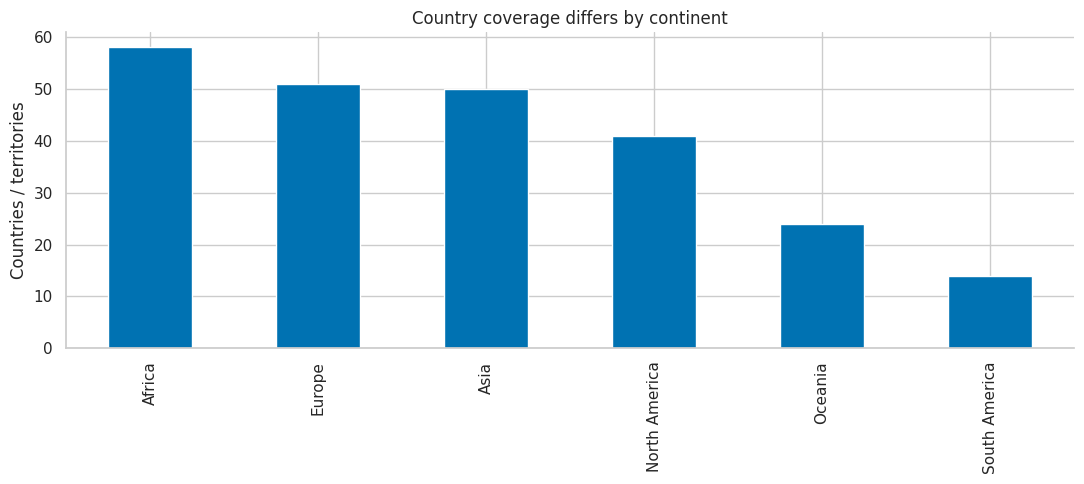

death_group,High,Low
continent,,
Africa,8,48
Asia,13,34
Europe,47,4
North America,31,10
Oceania,5,19
South America,12,2


death_group,High,Low
continent,,
Africa,0.143,0.857
Asia,0.277,0.723
Europe,0.922,0.078
North America,0.756,0.244
Oceania,0.208,0.792
South America,0.857,0.143


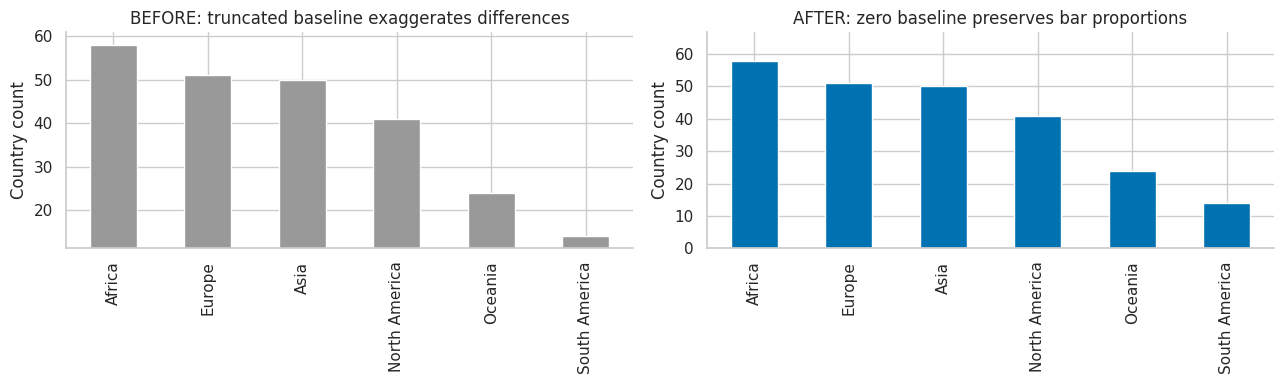

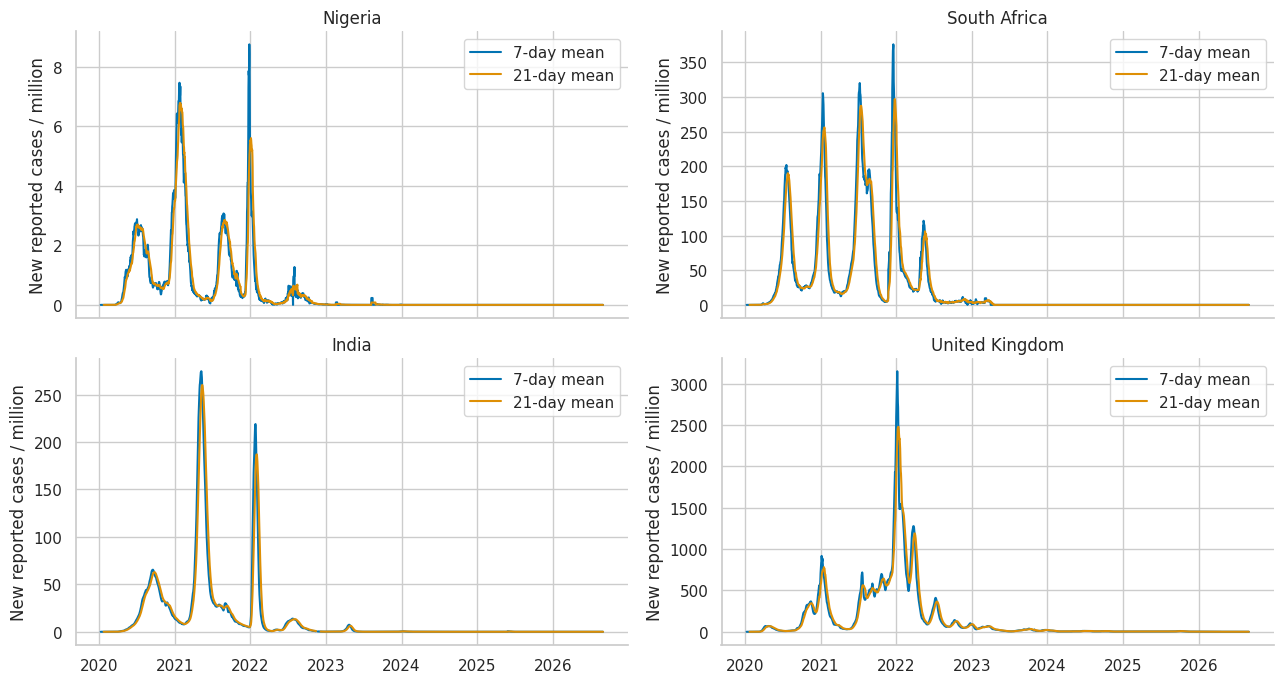

In [9]:
freq = country.continent.value_counts().rename_axis('continent').to_frame('countries')
freq['proportion'] = freq.countries / freq.countries.sum(); display(freq)
ax = freq.countries.plot.bar(color='#0072B2'); ax.set(ylabel='Countries / territories', title='Country coverage differs by continent', xlabel=''); save('continent_frequency')
median = country.total_deaths_per_million.median()
cat = country.dropna(subset=['continent','total_deaths_per_million']).copy()
cat['death_group'] = np.where(cat.total_deaths_per_million > median, 'High', 'Low')
display(pd.crosstab(cat.continent,cat.death_group))
display(pd.crosstab(cat.continent,cat.death_group,normalize='index').round(3))
fig, ax = plt.subplots(1,2,figsize=(13,4))
freq.countries.plot.bar(ax=ax[0],color='#999999'); ax[0].set_ylim(freq.countries.min()*0.8, freq.countries.max()*1.05); ax[0].set_title('BEFORE: truncated baseline exaggerates differences')
freq.countries.plot.bar(ax=ax[1],color='#0072B2'); ax[1].set_ylim(0,freq.countries.max()*1.15); ax[1].set_title('AFTER: zero baseline preserves bar proportions')
for a in ax: a.set_xlabel(''); a.set_ylabel('Country count')
save('before_after_bars')
selected = ['Nigeria','South Africa','India','United Kingdom']
fig, axes = plt.subplots(2,2,figsize=(13,7),sharex=True)
for name,a in zip(selected,axes.flat):
    ts = df[df.location.eq(name)].set_index('date').asfreq('D')
    series = ts.new_cases_per_million.mask(ts.new_cases_per_million < 0)
    for window in [7,21]:
        a.plot(series.rolling(window,min_periods=window).mean(),label=f'{window}-day mean')
    a.set(title=name,ylabel='New reported cases / million'); a.legend()
save('case_waves')
for name in selected:
    ts = df[df.location.eq(name)].set_index('date').new_cases_per_million
    s = ts.mask(ts<0).rolling(7,min_periods=7).mean()
    if s.notna().any(): print(f'{name}: highest 7-observation mean on {s.idxmax().date()}, {s.max():.1f} cases/million/day.')


The 7-day window retains shorter waves; 21 days provides a smoother overview but blurs peaks. Negative revisions are excluded from this visualization only. Gaps remain gaps; reporting frequency can change over time, so late low values do not prove transmission ended.

## Stage 3 · Descriptive statistics and correlation

Pooled Pearson correlation: 0.594
Distribution: right-skewed


,deaths_per_million
count,2.330000e+02
mean,1.275999e+03
median,8.893516e+02
var,1.789924e+06
std,1.337880e+03
skew,1.277494e+00
min,0.000000e+00
max,6.604006e+03


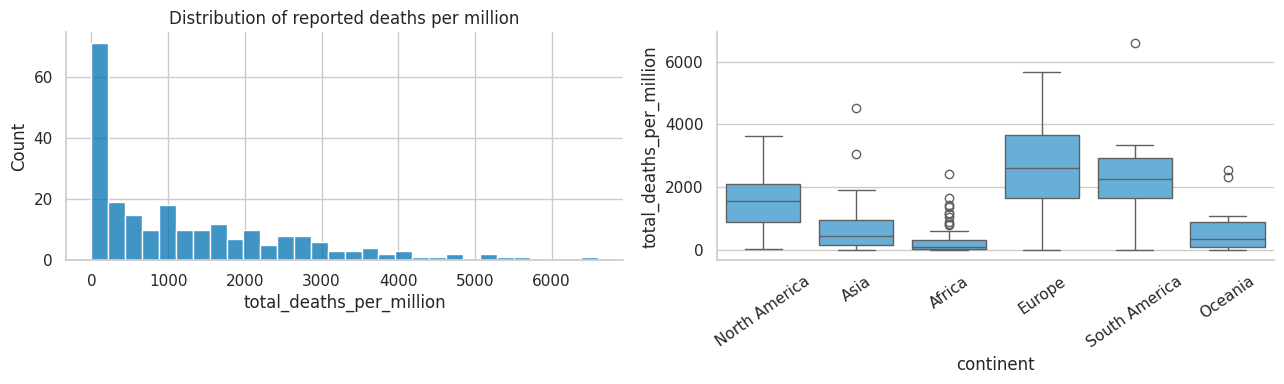

,location,continent,total_deaths_per_million
167,Peru,South America,6604.0063
20,Bulgaria,Europe,5681.0405
136,North Macedonia,Europe,5429.1950
23,Bosnia and Herzegovina,Europe,5123.2495
94,Hungary,Europe,5072.5360


,continent,n,pearson_r
0,Africa,56,0.506811
1,Asia,47,0.293347
2,Europe,51,0.027861
3,North America,41,0.368773
4,Oceania,23,0.465265
5,South America,14,-0.084948


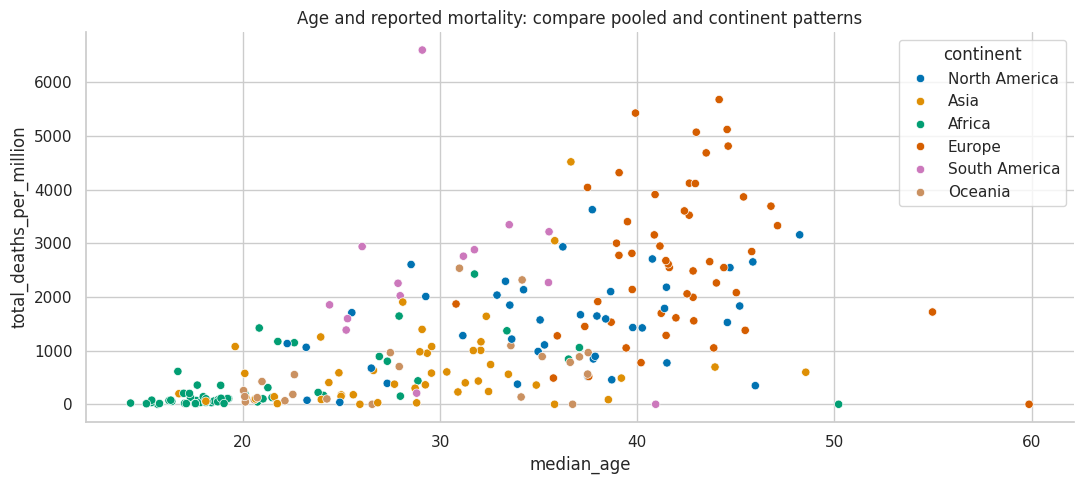

In [12]:
y = country.total_deaths_per_million.dropna()
stats = y.agg(['count','mean','median','var','std','skew','min','max'])
display(stats.to_frame('deaths_per_million'))
fig, ax = plt.subplots(1,2,figsize=(13,4))
sns.histplot(y,bins=30,ax=ax[0],color='#0072B2'); ax[0].set_title('Distribution of reported deaths per million')
sns.boxplot(data=country,x='continent',y='total_deaths_per_million',ax=ax[1],color='#56B4E9'); ax[1].tick_params(axis='x',rotation=35)
save('distribution_boxplots')
q1,q3 = y.quantile([.25,.75]); iqr=q3-q1
outliers = country[(country.total_deaths_per_million < q1-1.5*iqr) | (country.total_deaths_per_million > q3+1.5*iqr)]
display(outliers[['location','continent','total_deaths_per_million']].sort_values('total_deaths_per_million',ascending=False))
paired = country.dropna(subset=['median_age','total_deaths_per_million'])
r = paired.median_age.corr(paired.total_deaths_per_million)
within = pd.DataFrame([{'continent':c,'n':len(g),'pearson_r':g.median_age.corr(g.total_deaths_per_million) if len(g)>=3 else np.nan} for c,g in paired.groupby('continent')])
print('Pooled Pearson correlation:',round(r,3)); display(within)
sns.scatterplot(data=paired,x='median_age',y='total_deaths_per_million',hue='continent',palette='colorblind'); plt.title('Age and reported mortality: compare pooled and continent patterns'); save('age_mortality')
print('Distribution:', 'right-skewed' if stats['skew']>0 else 'left-skewed or symmetric')


Outliers are flagged for investigation, not deleted. Possible explanations include age structure, reporting completeness, epidemic timing and health-system stress. Compare the pooled coefficient with continent-specific signs and magnitudes above: a reversal would be consistent with a Simpson-type aggregation effect, but is not assumed. Correlation is not causation because country-level confounding and measurement differences can explain associations.

## Stage 4 · Spatial comparison
Sequential Viridis colours encode magnitude. Rates adjust for population size, but do not adjust for age or reporting quality. Counts instead describe absolute reported burden. A choropleth matches country-level observations; point maps imply precise locations, while cartograms make geographic recognition harder.

In [15]:
for metric,title,projection,name in [
 ('total_deaths_per_million','Reported deaths per million: geographic differences','natural earth','mortality_rate_natural_earth'),
 ('total_deaths','Total reported deaths: absolute burden','natural earth','mortality_counts'),
 ('total_deaths_per_million','Same mortality rates in Mercator projection','mercator','mortality_rate_mercator')]:
    fig = px.choropleth(country,locations='iso_code',color=metric,hover_name='location',
        hover_data=['total_deaths_per_million_date'],color_continuous_scale='Viridis',projection=projection,title=title)
    fig.update_layout(margin=dict(l=0,r=0,t=60,b=0))
    fig.write_html(OUT/(name+'.html'),include_plotlyjs=True); fig.show()


Mercator preserves local angles but greatly enlarges high latitudes; Natural Earth offers a world-view compromise, distorting shapes and areas. Neither eliminates ecological bias. Kosovo may lack a matching Plotly boundary. Missing countries are uncoloured. Moran’s I is an optional stretch and is not computed here.

## Stage 5 · Regression and clustering
Linear regression is **supervised** because known mortality outcomes train a predictor. K-means is **unsupervised** because it groups features without an outcome label. Reinforcement learning does not fit this static dataset because there is no sequential agent, action or reward process.

Predictors exclude case/death totals and other outcome-derived measures. Train/test splitting happens **before** fitting imputation and scaling. This is an exploratory cross-country holdout, not a prospective forecast; predictors can postdate part of the epidemic. Missing targets are excluded, and predictors with no training observations are removed.


Train/test sizes: 174 59
Selected k: 3
Cluster 0: median age 21.1; median GDP/person 6,726; beds/1,000 1.06.
Cluster 1: median age 38.2; median GDP/person 42,358; beds/1,000 3.48.
Cluster 2: median age 46.4; median GDP/person 117,098; beds/1,000 21.99.


,MAE,RMSE,R_squared
model,,,
Mean baseline,1006.663410,1221.379210,-0.017512
Linear regression,875.941023,1387.485113,-0.313092


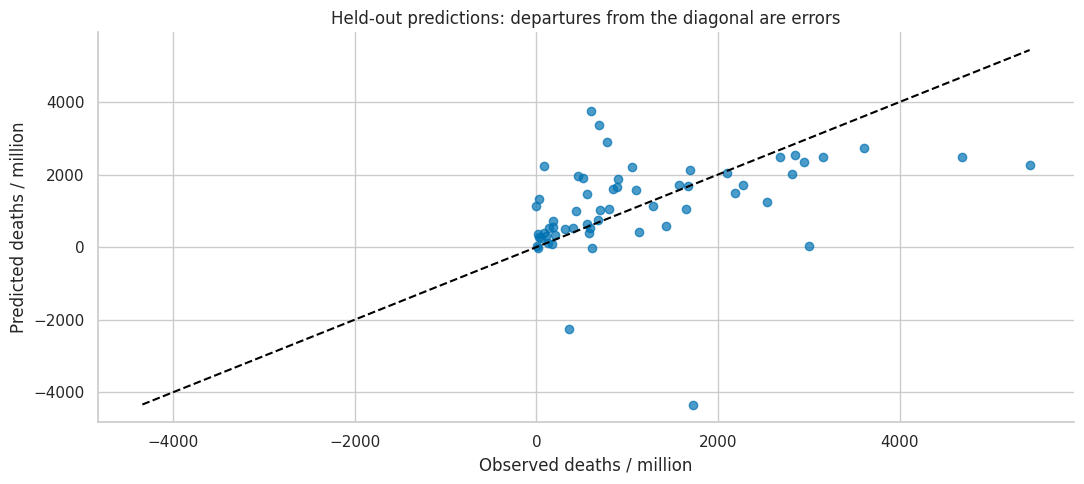

,silhouette
2,0.388722
3,0.408735
4,0.338959
5,0.371208
6,0.369904
7,0.294319
8,0.300319


,median_age,gdp_per_capita,hospital_beds_per_thousand,population_density,life_expectancy
cluster,,,,,
0,21.140000,6726.166992,1.06,76.367691,67.693848
1,38.198502,42357.988281,3.48,106.549347,78.066700
2,46.403000,117098.273438,21.99,20017.130859,83.924450


,countries,examples
cluster,,
0,106,"Afghanistan, Angola, American Samoa, Burundi, ..."
1,126,"Aruba, Anguilla, Albania, Andorra, United Arab..."
2,2,"Macao, Monaco"


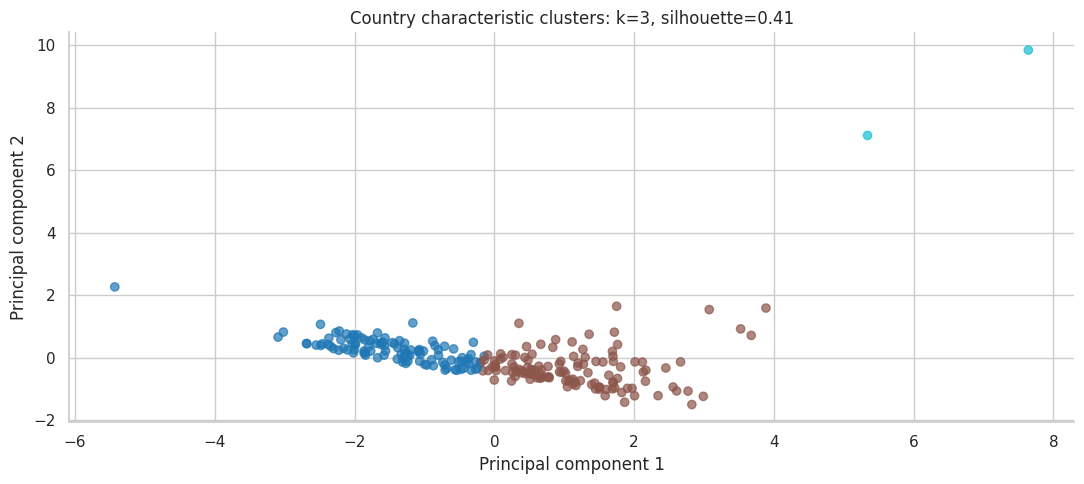

In [18]:
features = ['median_age','gdp_per_capita','hospital_beds_per_thousand','population_density','life_expectancy']
model_data = country.dropna(subset=['total_deaths_per_million']).copy()
X_train,X_test,y_train,y_test = train_test_split(model_data[features],model_data.total_deaths_per_million,test_size=.25,random_state=SEED)
features = [c for c in features if X_train[c].notna().any()]
X_train,X_test = X_train[features],X_test[features]
models = {'Mean baseline':make_pipeline(SimpleImputer(strategy='median'),DummyRegressor(strategy='mean')),
          'Linear regression':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LinearRegression())}
results=[]
for name,model in models.items():
    model.fit(X_train,y_train); pred=model.predict(X_test)
    results.append({'model':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R_squared':r2_score(y_test,pred)})
metrics = pd.DataFrame(results).set_index('model'); display(metrics)
metrics.to_csv(OUT/'regression_metrics.csv')
pred = models['Linear regression'].predict(X_test)
plt.scatter(y_test,pred,color='#0072B2',alpha=.7)
lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max()); plt.plot([lo,hi],[lo,hi],'--',color='black')
plt.xlabel('Observed deaths / million'); plt.ylabel('Predicted deaths / million'); plt.title('Held-out predictions: departures from the diagonal are errors'); save('regression_predictions')
print('Train/test sizes:',len(y_train),len(y_test))
# Cluster on characteristics only. Restrict to countries with at least 3 observed predictors.
cluster_data = country[country[features].notna().sum(axis=1)>=3].copy()
preprocessor = make_pipeline(SimpleImputer(strategy='median'),StandardScaler())
Z = preprocessor.fit_transform(cluster_data[features])
scores = {}
for k in range(2, min(9,len(Z))):
    labels=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit_predict(Z)
    scores[k]=silhouette_score(Z,labels)
best_k=max(scores,key=scores.get)
cluster_data['cluster']=KMeans(n_clusters=best_k,n_init=20,random_state=SEED).fit_predict(Z)
display(pd.Series(scores,name='silhouette').to_frame())
print('Selected k:',best_k)
profile=cluster_data.groupby('cluster')[features].median(); display(profile)
display(cluster_data.groupby('cluster').agg(countries=('location','count'),examples=('location',lambda s:', '.join(s.head(5)))))
for label,row in profile.iterrows():
    print(f'Cluster {label}: median age {row.median_age:.1f}; median GDP/person {row.gdp_per_capita:,.0f}; beds/1,000 {row.hospital_beds_per_thousand:.2f}.')
components=PCA(n_components=2,random_state=SEED).fit_transform(Z)
plt.scatter(components[:,0],components[:,1],c=cluster_data.cluster,cmap='tab10',alpha=.7)
plt.xlabel('Principal component 1'); plt.ylabel('Principal component 2'); plt.title(f'Country characteristic clusters: k={best_k}, silhouette={scores[best_k]:.2f}'); save('clusters_pca')
cluster_data.to_csv(ROOT/'data/clean/country_clusters.csv',index=False)


MAE and RMSE are in deaths per million; lower is better. R² can be negative when a model generalizes poorly. Negative linear predictions are retained for transparent evaluation and flag the model’s limitations. K-means depends on scaling, selected features, imputation and outliers; cluster numbers have no rank or causal meaning. Silhouette selects compact, separated groups rather than proving real country “types”.

## Stage 6 · Reproducibility and data management
The project includes the immutable raw snapshot, source date and SHA-256, cleaned tables, output charts, README and requirements. Random seeds are fixed. Relative paths work from the project root or notebook folder. Package versions are recorded below.

**Teammate test: PENDING.** A second person must follow the README on their own machine and complete `peer_test.md`. This notebook cannot claim that independent test occurred. The README provides a seven-stage Git commit checklist; no invented commit history is supplied.


In [21]:
import importlib.metadata
versions = {pkg:importlib.metadata.version(pkg) for pkg in ['pandas','numpy','matplotlib','seaborn','plotly','scikit-learn','pycountry','nbformat','nbclient','ipykernel']}
manifest={'url':URL,'sha256':sha256,'source_metadata':json.loads(metadata_path.read_text()) if metadata_path.exists() else {},'python':sys.version,'platform':platform.platform(),'packages':versions,'seed':SEED}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
(ROOT/'requirements.txt').write_text('\n'.join(f'{key}=={value}' for key,value in versions.items())+'\n')
pd.DataFrame(log).to_csv(OUT/'cleaning_log.csv',index=False)
display(pd.DataFrame(log)); display(pd.Series(versions,name='version'))


,decision,rows_affected
0,Remove aggregate and non-country codes using e...,45288
1,Drop invalid dates,0
2,Latest nonmissing value per field; retain fiel...,238


pandas            2.2.3
numpy             2.3.5
matplotlib       3.10.8
seaborn          0.13.2
plotly            7.1.0
scikit-learn      1.8.0
pycountry       26.2.16
nbformat         5.11.1
nbclient         0.11.0
ipykernel         7.4.0
Name: version, dtype: object

## Stage 7 · Redesign and communication
Three redesigns: (1) the continent bars restore a zero baseline and remove decorative clutter; (2) the time-series overview becomes a direct comparison of per-capita smoothed rates; (3) the mortality/age relationship uses transparent points, an explicit association title and a Nigeria highlight. The before/after pair appears in Stage 2. The map uses a sequential colour scale, and category plots use a colour-blind-friendly palette.

The one-page summary below combines these three redesigned visuals. Latest mortality dates vary by country; consult the dated table before interpreting rankings.


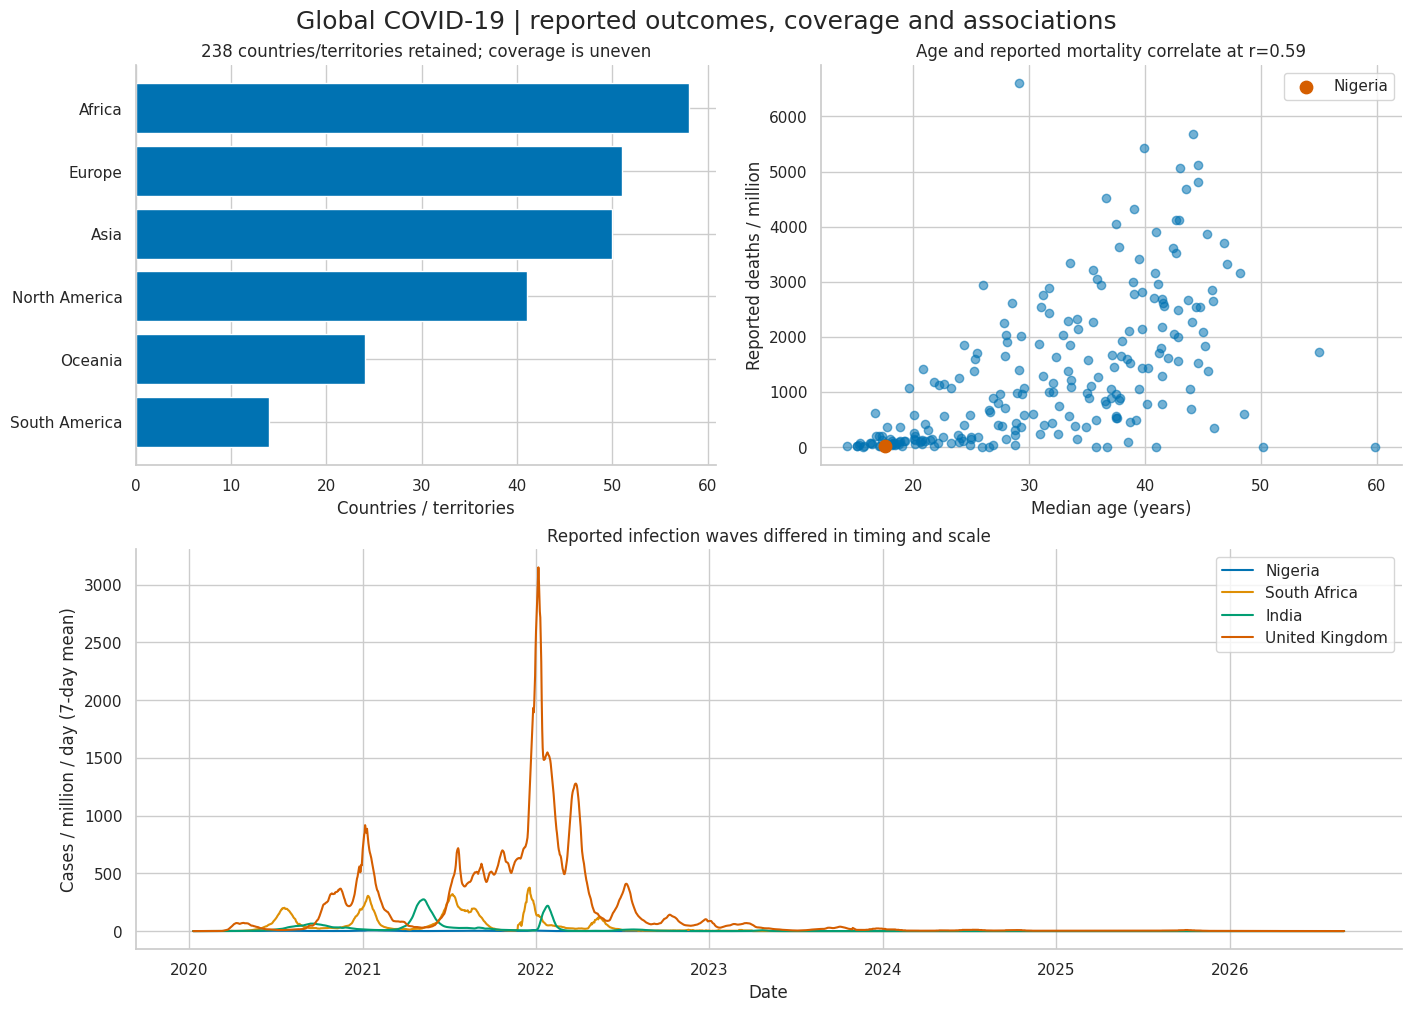

The analysis retains 238 countries and territories with observations spanning 2020-01-01 to 2026-08-30. Across 233 countries with an observed mortality rate, median reported cumulative deaths were 889.4 per million, compared with a mean of 1,276.0. Peru had the highest recorded rate in this snapshot at 6,604.0 deaths per million. Nigeria recorded 14.1 reported deaths per million as of 2026-08-30. Median age and reported deaths per million had a pooled Pearson correlation of 0.59, with continent-specific results shown in Stage 3. On the held-out test set, linear regression achieved MAE 875.9, RMSE 1,387.5 and R-squared -0.313. The mean baseline achieved MAE 1,006.7 and RMSE 1,221.4, providing a reference for judging added predictive value. K-means selected 3 groups with silhouette 0.409; these summarize country characteristics rather than causal mechanisms. Differences in testing, death reporting, predictor measurement dates and outcome freshness limit fair comparisons. These ecological associations cannot establish causality or justify individual-level conclusions.

In [23]:
fig = plt.figure(figsize=(14,10),layout='constrained')
grid=fig.add_gridspec(2,2)
a=fig.add_subplot(grid[0,0]); order=freq.countries.sort_values()
a.barh(order.index,order.values,color='#0072B2'); a.set(title=f'{len(country)} countries/territories retained; coverage is uneven',xlabel='Countries / territories')
b=fig.add_subplot(grid[0,1]); b.scatter(paired.median_age,paired.total_deaths_per_million,color='#0072B2',alpha=.55)
ng=paired[paired.location.eq('Nigeria')]
b.scatter(ng.median_age,ng.total_deaths_per_million,color='#D55E00',s=80,label='Nigeria'); b.legend()
b.set(title=f'Age and reported mortality correlate at r={r:.2f}',xlabel='Median age (years)',ylabel='Reported deaths / million')
c=fig.add_subplot(grid[1,:])
for name in selected:
    ts=df[df.location.eq(name)].set_index('date').asfreq('D')
    c.plot(ts.index,ts.new_cases_per_million.mask(ts.new_cases_per_million<0).rolling(7,min_periods=7).mean(),label=name)
c.set(title='Reported infection waves differed in timing and scale',ylabel='Cases / million / day (7-day mean)',xlabel='Date'); c.legend()
fig.suptitle('Global COVID-19 | reported outcomes, coverage and associations',fontsize=18)
fig.savefig(OUT/'one_page_summary.png',dpi=160,bbox_inches='tight'); plt.show()
valid=country.dropna(subset=['total_deaths_per_million'])
top=valid.loc[valid.total_deaths_per_million.idxmax()]
ng=valid[valid.location.eq('Nigeria')]
lin=metrics.loc['Linear regression']; base=metrics.loc['Mean baseline']
summary=[
f'The analysis retains {len(country)} countries and territories with observations spanning {df.date.min().date()} to {df.date.max().date()}.',
f'Across {len(valid)} countries with an observed mortality rate, median reported cumulative deaths were {y.median():,.1f} per million, compared with a mean of {y.mean():,.1f}.',
f'{top.location} had the highest recorded rate in this snapshot at {top.total_deaths_per_million:,.1f} deaths per million.',
f'Nigeria recorded {ng.total_deaths_per_million.iloc[0]:,.1f} reported deaths per million as of {ng.total_deaths_per_million_date.iloc[0].date()}.' if len(ng) else 'Nigeria lacked a usable mortality observation in this snapshot.',
f'Median age and reported deaths per million had a pooled Pearson correlation of {r:.2f}, with continent-specific results shown in Stage 3.',
f'On the held-out test set, linear regression achieved MAE {lin.MAE:,.1f}, RMSE {lin.RMSE:,.1f} and R-squared {lin.R_squared:.3f}.',
f'The mean baseline achieved MAE {base.MAE:,.1f} and RMSE {base.RMSE:,.1f}, providing a reference for judging added predictive value.',
f'K-means selected {best_k} groups with silhouette {scores[best_k]:.3f}; these summarize country characteristics rather than causal mechanisms.',
'Differences in testing, death reporting, predictor measurement dates and outcome freshness limit fair comparisons.',
'These ecological associations cannot establish causality or justify individual-level conclusions.'
]
text=' '.join(summary)
(OUT/'findings_summary.md').write_text('# Findings summary\n\n'+text+'\n')
display(Markdown(text))


## One-line stage reflections
These are implementation reflections, not a claim of personal classroom experience.
1. **Types/pipeline:** The compact schema differed from the brief; explicit alias normalization and validation resolved it.
2. **Categories/time series:** Daily rows would bias country counts; one-country summaries and daily reindexing made comparisons clearer.
3. **Statistics:** Missing recent outcomes could erase history; latest nonmissing values with their own dates preserved traceability.
4. **Maps:** Counts favour large populations; paired rate/count maps and projection notes clarified the distinction.
5. **Models:** Preprocessing could leak information; fitting the regression pipeline only on training countries avoided that error.
6. **Reproducibility:** A live URL can change; the immutable snapshot, hash and environment manifest support replay.
7. **Visualization:** Truncated bars exaggerated differences; zero baselines, clear labels and per-capita trends improved communication.

## Sources
- Assignment: supplied **Week_4_Project.pdf**, Global COVID-19 Data Explorer.
- Requested data: https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv
- OWID data documentation and attribution: https://docs.owid.io/projects/covid/en/latest/
- Dataset variables and source metadata should be consulted before interpreting units or historical comparability. Optional stretch work not implemented: Moran’s I, random forest and an independent audience review.
